# One-day Value at Risk and expected shortfall, with backtests

This notebook documents how CryptoQuantLab estimates one-day VaR and expected shortfall, and how it tests them. Four methods are estimated from a 180-day window and each is backtested out of sample on every later day.

The reference implementation is [`cql_validation/var.py`](../cql_validation/var.py). The TypeScript models in [`valueAtRisk.ts`](../../backend/src/models/valueAtRisk.ts) and [`varBacktest.ts`](../../backend/src/models/varBacktest.ts) reproduce every exception day below exactly, and the test statistics to 1e-10.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox

sys.path.insert(0, str(Path.cwd().parent))
from cql_validation import garch, garch_diagnostics, returns, var

plt.rcParams.update({"figure.figsize": (9, 3.4), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

btc = pd.read_csv("../data/bitcoin_usd_daily.csv", parse_dates=["date"])
prices = btc["price_usd"].to_numpy()
dates = btc["date"]
periods_per_year = returns.periods_per_year(btc["timestamp_ms"].to_numpy())
print(f"{len(prices)} daily closes, {dates.iloc[0]:%Y-%m-%d} to {dates.iloc[-1]:%Y-%m-%d}; {periods_per_year:.2f} observations per year")

364 daily closes, 2025-10-23 to 2026-10-21; 365.25 observations per year


## 1. Definitions

VaR and ES are computed on simple returns $R_t = P_t / P_{t-1} - 1$, so a position's dollar loss is exactly $-R_t$ times its size. At tail probability $\alpha = 1 - c$,

$$\text{VaR}_\alpha = -Q_\alpha(R), \qquad \text{ES}_\alpha = -\mathbb{E}\left[R \mid R \le Q_\alpha(R)\right].$$

The four estimators:

| Method | VaR | ES |
|---|---|---|
| Historical | empirical quantile (linear interpolation) | mean of returns at or below it |
| Normal | $-(\mu + \sigma z_\alpha)$ | $-(\mu - \sigma\,\varphi(z_\alpha)/\alpha)$ |
| Student-t, maximum likelihood | $-(\mu + s\,q)$, $q = t_\nu^{-1}(\alpha)$ | $-\left(\mu - s\,\frac{f_\nu(q)}{\alpha}\cdot\frac{\nu + q^2}{\nu - 1}\right)$ |
| GARCH-filtered historical simulation | $1 - e^{\mu + \sigma_{T+1} Q_\alpha(z)}$ | mean of $1 - e^{\mu + \sigma_{T+1} z}$ over $z \le Q_\alpha(z)$ |

In the filtered method, a GARCH(1,1) fitted to the window's log returns gives tomorrow's volatility $\sigma_{T+1}$ and the standardized residuals $z$ give the shape of a bad day.

In [2]:
WINDOW = 180
R = returns.simple_returns(prices)
latest = R[-WINDOW:]
t_fit = var.fit_student_t(latest)
filtered = var.fit_filtered(latest)
estimates = {}
for confidence in (0.95, 0.99):
    a = 1 - confidence
    estimates[("historical", confidence)] = var.historical(latest, a)
    estimates[("normal", confidence)] = var.normal(latest, a)
    estimates[("Student-t", confidence)] = var.student_t(latest, a, t_fit)
    estimates[("GARCH-filtered", confidence)] = var.filtered_historical(latest, a, filtered)
table = pd.DataFrame(estimates, index=["VaR", "ES"]).T * 100
table.index.names = ["method", "confidence"]
table.round(2).unstack("confidence")

VaR        ES     
confidence     0.95 0.99 0.95 0.99
method                            
GARCH-filtered 2.42 3.16 3.16 4.21
Student-t      2.93 5.45 4.65 8.07
historical     2.64 4.11 3.63 5.45
normal          3.1 4.41  3.9 5.06

Expected shortfall rises much faster than VaR from the normal to the Student-t: with roughly three degrees of freedom the fitted tail is heavy, so the average loss beyond the 99% VaR is far above the VaR itself.

In [3]:
scipy_dof, scipy_loc, scipy_scale = stats.t.fit(latest)
pd.DataFrame(
    {
        "reference (scipy, polished)": [t_fit.dof, t_fit.location, t_fit.scale, t_fit.log_likelihood],
        "scipy t.fit": [scipy_dof, scipy_loc, scipy_scale, float(np.sum(stats.t.logpdf(latest, scipy_dof, scipy_loc, scipy_scale)))],
    },
    index=["degrees of freedom ν", "location", "scale", "log-likelihood"],
)

,"reference (scipy, polished)",scipy t.fit
degrees of freedom ν,3.28837,3.28836
location,-0.000320587,-0.000320632
scale,0.0127793,0.0127794
log-likelihood,471.381,471.381


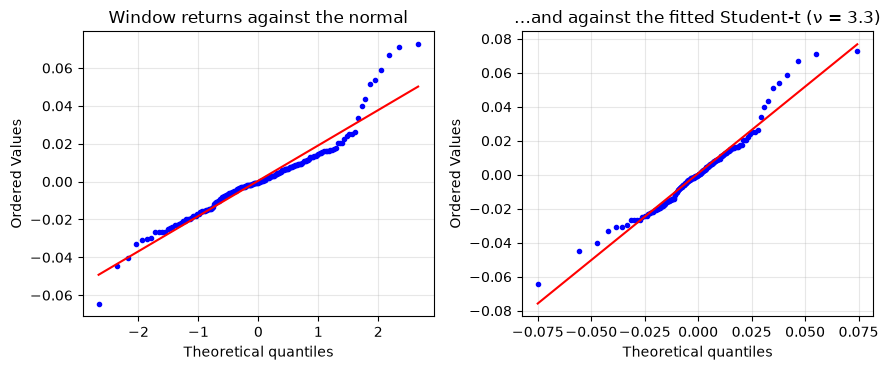

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))
stats.probplot(latest, dist="norm", plot=ax1)
ax1.set_title("Window returns against the normal")
stats.probplot(latest, dist=stats.t, sparams=(t_fit.dof, t_fit.location, t_fit.scale), plot=ax2)
ax2.set_title(f"…and against the fitted Student-t (ν = {t_fit.dof:.1f})")
for ax in (ax1, ax2):
    ax.get_lines()[0].set_markersize(3)
fig.tight_layout()

## 2. Out-of-sample backtest

For each day $t$ after the first 180, VaR is estimated from the 180 returns before $t$ only, and an exception is a day whose loss exceeds it. The fits are cached per day so both confidence levels share them.

In [5]:
methods = {"historical": "historical", "normal": "normal", "Student-t": "studentT", "GARCH-filtered": "filteredHistorical"}
cache = {name: {} for name in methods.values()}
test_dates = dates.iloc[WINDOW + 1 :].reset_index(drop=True)
paths, hits = {}, {}
for label, name in methods.items():
    for confidence in (0.95, 0.99):
        a = 1 - confidence
        series = []
        for t in range(WINDOW, len(R)):
            sample = R[t - WINDOW : t]
            if name == "studentT":
                cache[name].setdefault(t, var.fit_student_t(sample))
                series.append(var.student_t(sample, a, cache[name][t])[0])
            elif name == "filteredHistorical":
                cache[name].setdefault(t, var.fit_filtered(sample))
                series.append(var.filtered_historical(sample, a, cache[name][t])[0])
            else:
                series.append(var.METHODS[name](sample, a)[0])
        paths[(label, confidence)] = np.array(series)
        hits[(label, confidence)] = R[WINDOW:] < -paths[(label, confidence)]
print(f"{len(test_dates)} test days, {test_dates.iloc[0]:%Y-%m-%d} to {test_dates.iloc[-1]:%Y-%m-%d}")

183 test days, 2026-04-22 to 2026-10-21


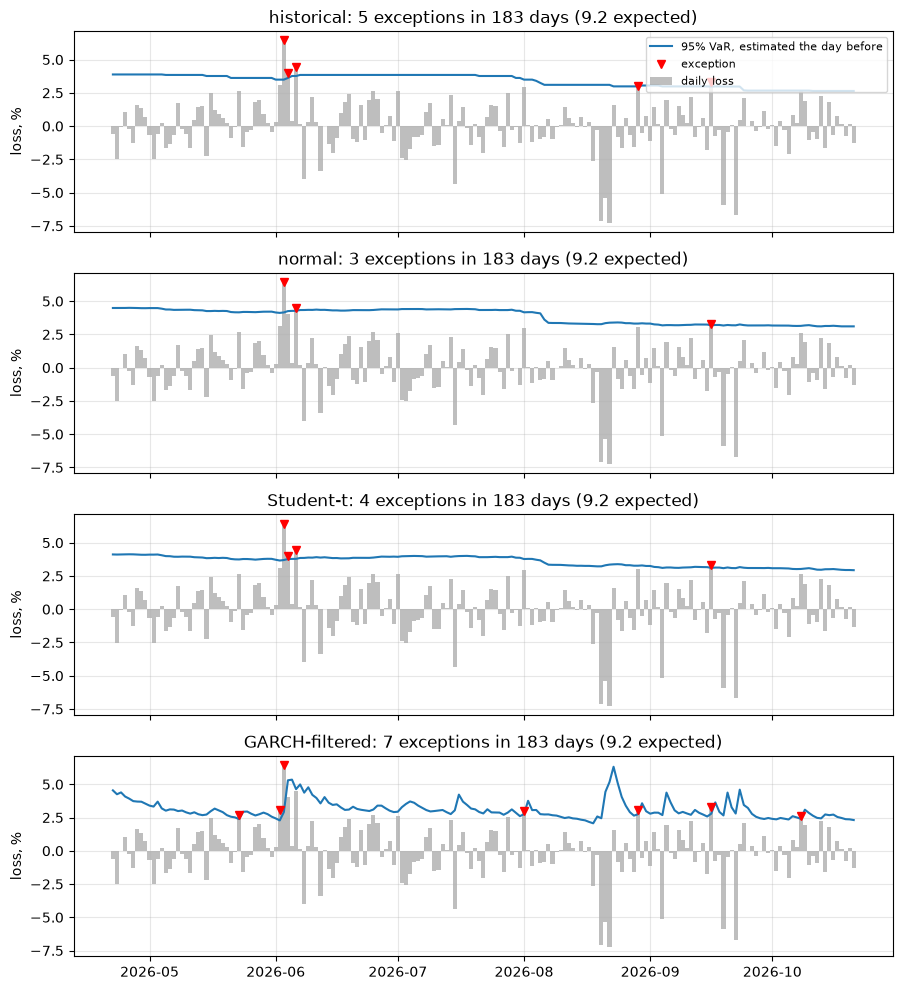

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(9, 10), sharex=True, sharey=True)
loss = -R[WINDOW:] * 100
for ax, label in zip(axes, methods):
    path = paths[(label, 0.95)] * 100
    exceptions = hits[(label, 0.95)]
    ax.bar(test_dates, loss, color="tab:gray", width=1.0, alpha=0.5, label="daily loss")
    ax.plot(test_dates, path, color="tab:blue", linewidth=1.5, label="95% VaR, estimated the day before")
    ax.plot(test_dates[exceptions], loss[exceptions], "rv", markersize=6, label="exception")
    ax.set_title(f"{label}: {exceptions.sum()} exceptions in {len(exceptions)} days ({0.05 * len(exceptions):.1f} expected)")
    ax.set_ylabel("loss, %")
axes[0].legend(loc="upper right", fontsize=8)
fig.tight_layout()

The historical and Student-t lines move slowly because every day in the window counts equally. The GARCH-filtered line reacts within days of a large move and falls back in calm periods, which is why its exceptions are closest to the expected count.

## 3. Coverage tests

With $x$ exceptions in $n$ days, Kupiec's unconditional coverage test compares the exception rate with $\alpha$:

$$LR_{uc} = -2\ln\left[(1-\alpha)^{n-x}\alpha^{x}\right] + 2\ln\left[\left(1-\tfrac{x}{n}\right)^{n-x}\left(\tfrac{x}{n}\right)^{x}\right] \sim \chi^2_1.$$

Christoffersen's test asks whether an exception makes another one tomorrow more likely, from the counts $n_{ij}$ of days in state $j$ after a day in state $i$, and $LR_{cc} = LR_{uc} + LR_{ind} \sim \chi^2_2$ tests both at once. A method passes on the Risk tab when both the Kupiec and conditional coverage p-values are at least 0.05.

In [7]:
rows = []
for (label, confidence), h in hits.items():
    a = 1 - confidence
    lr_uc, p_uc = var.kupiec(list(h), a)
    lr_ind, p_ind = var.christoffersen(list(h))
    p_cc = float(stats.chi2.sf(lr_uc + lr_ind, 2))
    rows.append({
        "method": label, "confidence": confidence, "exceptions": int(h.sum()), "expected": a * len(h),
        "Kupiec p": p_uc, "Christoffersen p": p_ind, "conditional coverage p": p_cc,
        "passes": p_uc >= 0.05 and p_cc >= 0.05,
    })
pd.DataFrame(rows).set_index(["confidence", "method"]).sort_index()

exceptions  expected  Kupiec p  Christoffersen p  \
confidence method                                                             
0.95       GARCH-filtered           7      9.15  0.447621           0.24867   
           Student-t                4      9.15 0.0503009         0.0611368   
           historical               5      9.15  0.124872          0.108546   
           normal                   3      9.15 0.0158073          0.751155   
0.99       GARCH-filtered           1      1.83  0.499892          0.916282   
           Student-t                0      1.83  0.055121                 1   
           historical               1      1.83  0.499892          0.916282   
           normal                   1      1.83  0.499892          0.916282   

                           conditional coverage p  passes  
confidence method                                          
0.95       GARCH-filtered                0.385307    True  
           Student-t                    0.0255061   False  
           historical                   0.0849921    True  
           normal                        0.051696   False  
0.99       GARCH-filtered                0.792069    True  
           Student-t                     0.158943    True  
           historical                    0.792069    True  
           normal                        0.792069    True

## 4. How much can a one-year backtest tell us?

With about 185 test days, few exceptions are expected at 99%, so the test can only detect large errors. The cell below computes the probability that Kupiec's test rejects, at the 5% level, when the true exception rate differs from the nominal one. Exceptions are binomial when the model's exception days are independent.

In [8]:
n = len(test_dates)


def rejection_probability(nominal, true_rate):
    x = np.arange(n + 1)
    p_values = np.array([var.kupiec([True] * k + [False] * (n - k), nominal)[1] for k in x])
    return float(stats.binom.pmf(x[p_values < 0.05], n, true_rate).sum())


true_rates = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10]
pd.DataFrame(
    {"95% VaR": [rejection_probability(0.05, q) for q in true_rates], "99% VaR": [rejection_probability(0.01, q) for q in true_rates]},
    index=pd.Index([f"{q:.1%}" for q in true_rates], name="true exception rate"),
).round(3)

,95% VaR,99% VaR
true exception rate,,
0.5%,0.986,0
1.0%,0.887,0.011
2.0%,0.501,0.162
3.0%,0.199,0.471
5.0%,0.039,0.899
7.5%,0.299,0.995
10.0%,0.749,1


A 99% VaR that is actually breached on 2% of days, twice as often as it should be, is rejected only a minority of the time with one year of data. A pass at 99% is therefore weak evidence, which is why the Risk tab says so. The 95% test has more power, and it is the level at which the methods differ: the normal model fails by being too cautious and the GARCH-filtered method comes closest to the nominal rate.

## 5. Limitations

- **Short history.** CoinGecko's demo key reaches back 365 days, leaving about 185 test days after the first window. The history grows by a day each night.
- **One day only.** Ten-day VaR needs simulation (bootstrapped GARCH paths), not the square-root-of-time rule, given these tails.
- **Single assets.** Portfolio VaR needs a covariance model; Ledoit-Wolf shrinkage is planned.
- **Backtest power,** as section 4 shows.

## References

- Barone-Adesi, G., Giannopoulos, K. and Vosper, L. (1999). VaR without correlations for portfolios of derivative securities. *Journal of Futures Markets*, 19(5), 583–602.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- McNeil, A. J., Frey, R. and Embrechts, P. (2015). *Quantitative Risk Management: Concepts, Techniques and Tools*, revised edition. Princeton University Press.